# Бустинг и стекинг

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

В работе используется база данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированная на основе записей участников, выполнявших повседневные действия с смартфоном со встроенными инерционными датчиками. Цель — классифицировать действие по одному из шести видов: ходьба, подъём по лестнице, спуск по лестнице, сидение, стояние и лежание.

Для каждой записи даны трёхосное ускорение с акселерометра (общее и ускорение тела), трёхосная угловая скорость с гироскопа, вектор из 561 признака во временной и частотной областях и метка вида деятельности.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('scikit-learn-intelex не установлен — используется стандартный scikit-learn')

%matplotlib inline

scikit-learn-intelex не установлен — используется стандартный scikit-learn


## Вопрос 1. Импорт и изучение данных

На данном этапе выполняется:

- импорт данных из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и изучение структуры и типов данных (типов слишком много для перечисления по столбцам, поэтому они группируются по количеству);
- определение того, требуется ли масштабирование столбцов типа float.

In [2]:
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)

(10299, 562)


Количество столбцов по типам данных.

In [3]:
data.dtypes.astype(str).value_counts()

float64    561
str          1
Name: count, dtype: int64

Единственный столбец не типа float — целевой (в файле он называется `Activity`).

In [4]:
data.columns[data.dtypes.astype(str) != 'float64']

Index(['Activity'], dtype='str')

Минимальное и максимальное значения среди всех столбцов типа float.

In [5]:
float_cols = data.columns[data.dtypes.astype(str) == 'float64']
print('Минимум:', data[float_cols].min().min())
print('Максимум:', data[float_cols].max().max())

Минимум: -1.0
Максимум: 1.0


### Выводы к вопросу 1

* Набор содержит 10 299 записей и 562 столбца: 561 признак типа `float64` и один строковый целевой столбец `Activity` (в задании он назван `categories`).
* Все признаки лежат в диапазоне от −1,0 до 1,0, то есть уже нормированы. К тому же модели на основе деревьев (в том числе бустинг) не чувствительны к масштабу, поэтому **масштабирование не требуется**.

## Вопрос 2. Кодирование и разбиение данных

На данном этапе выполняется:

- присвоение действиям целочисленных кодов;
- разбиение данных на обучающую и тестовую выборки; принимается решение о необходимости стратификации.

In [6]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])
print(dict(zip(range(len(le.classes_)), le.classes_)))
data['Activity'].value_counts(normalize=True).sort_index().round(4)

{0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}


Activity
0    0.1888
1    0.1725
2    0.1851
3    0.1672
4    0.1365
5    0.1499
Name: proportion, dtype: float64

Выборка разбивается на обучающую и тестовую **без** стратификации: классы почти равномерны (от 14 % до 19 %), а бустинг — достаточно мощная модель, поэтому дисбаланс не угрожает. Для ускорения поиска по сетке `data` можно уменьшить, но здесь используется весь набор данных.

In [7]:
feature_cols = [x for x in data.columns if x != 'Activity']
X_train, X_test, y_train, y_test = train_test_split(data[feature_cols], data['Activity'],
                                                    test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)
pd.DataFrame({'train': y_train.value_counts(normalize=True).sort_index(),
              'test': y_test.value_counts(normalize=True).sort_index()}).round(4)

(7209, 561) (3090, 561)


,train,test
Activity,,
0,0.1868,0.1932
1,0.1684,0.1822
2,0.1885,0.1770
3,0.1641,0.1744
4,0.1368,0.1359
5,0.1554,0.1372


### Выводы к вопросу 2

* Шесть видов активности закодированы целыми числами 0–5 (`LabelEncoder`: 0 — LAYING, 1 — SITTING, 2 — STANDING, 3 — WALKING, 4 — WALKING_DOWNSTAIRS, 5 — WALKING_UPSTAIRS).
* Классы почти сбалансированы (доли от 13,7 % до 18,9 %), а бустинг — достаточно устойчивая модель, поэтому разбиение 70 % / 30 % (7 209 обучающих и 3 090 тестовых записей, `random_state = 42`) выполнено **без стратификации**. Доли классов в обеих выборках различаются лишь на 1–2 п.п., то есть тестовая выборка пригодна для оценки.

## Вопрос 3. Градиентный бустинг: число деревьев

На данном этапе выполняется:

- построение моделей градиентного бустинга с параметрами по умолчанию для `n_estimators = [25, 50, 100, 200, 400]` и оценка точности на тестовых данных;
- построение графика зависимости точности от числа оценок.

Для ускорения задан `max_features=4`. Флаг `warm_start` не используется: модель создаётся в цикле заново для каждого значения `n_estimators`, поскольку бустинговые модели не имеют ошибки out-of-bag.

In [8]:
import time
n_list = [25, 50, 100, 200, 400]
acc_list = []
for n in n_list:
    t0 = time.time()
    gbc = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42).fit(X_train, y_train)
    acc_list.append(accuracy_score(y_test, gbc.predict(X_test)))
    print(f'n_estimators={n:>3}: точность на тесте = {acc_list[-1]:.4f}  ({time.time() - t0:.1f} с)')

gb_acc = pd.Series(acc_list, index=n_list, name='accuracy')

n_estimators= 25: точность на тесте = 0.9311  (0.7 с)


n_estimators= 50: точность на тесте = 0.9595  (1.5 с)


n_estimators=100: точность на тесте = 0.9764  (3.0 с)


n_estimators=200: точность на тесте = 0.9841  (5.9 с)


n_estimators=400: точность на тесте = 0.9867  (11.8 с)


График зависимости точности от количества оценок.

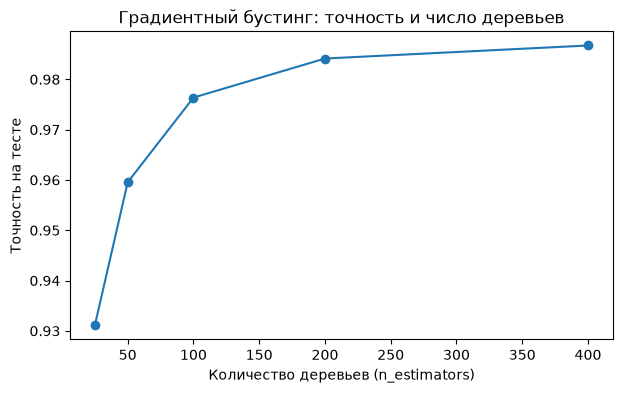

In [9]:
ax = gb_acc.plot(marker='o', figsize=(7, 4))
ax.set(xlabel='Количество деревьев (n_estimators)', ylabel='Точность на тесте',
       title='Градиентный бустинг: точность и число деревьев');

### Выводы к вопросу 3

* Точность на тесте растёт с числом деревьев: 0,931 (25) → 0,960 (50) → 0,976 (100) → 0,984 (200) → 0,987 (400).
* Выигрыш затухает: переход от 25 к 100 деревьям даёт +4,5 п.п., от 200 к 400 — лишь +0,3 п.п., а время обучения при этом удваивается (5,9 с → 11,8 с).
* В отличие от баггинга, деревья в бустинге обучаются **последовательно**, каждое исправляет ошибки предыдущих, поэтому для снижения смещения нужно достаточное число деревьев; при малом числе модель недообучена.

## Вопрос 4. Градиентный бустинг с поиском по сетке

На данном этапе выполняется:

- поиск по сетке с перекрёстной валидацией (`GridSearchCV`) для градиентного бустинга: перебираются число оценок, скорость обучения, доля подвыборки и максимальное число признаков;
- анализ параметров лучшей модели;
- расчёт метрик ошибок и анализ матрицы путаницы.

In [10]:
param_grid = {'n_estimators': [100, 200, 400],
              'learning_rate': [0.1, 0.01],
              'subsample': [1.0, 0.5],
              'max_features': [4, 8]}

GV_GBC = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1)
GV_GBC = GV_GBC.fit(X_train, y_train)
gbc_best = GV_GBC.best_estimator_

print('Лучшие параметры:', GV_GBC.best_params_)
print('Точность кросс-валидации:', round(GV_GBC.best_score_, 4))

Лучшие параметры: {'learning_rate': 0.1, 'max_features': 8, 'n_estimators': 400, 'subsample': 0.5}
Точность кросс-валидации: 0.987


Показатели ошибок. Отчёт о классификации особенно удобен в случаях с несколькими классами.

In [11]:
y_pred_gbc = gbc_best.predict(X_test)
print(classification_report(y_test, y_pred_gbc, target_names=le.classes_))
print('accuracy на тесте:', round(accuracy_score(y_test, y_pred_gbc), 4))

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.98      0.96      0.97       563
          STANDING       0.97      0.98      0.97       547
           WALKING       1.00      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      1.00      1.00       420
  WALKING_UPSTAIRS       0.99      1.00      0.99       424

          accuracy                           0.99      3090
         macro avg       0.99      0.99      0.99      3090
      weighted avg       0.99      0.99      0.99      3090

accuracy на тесте: 0.9883


Матрица путаницы.

{0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}


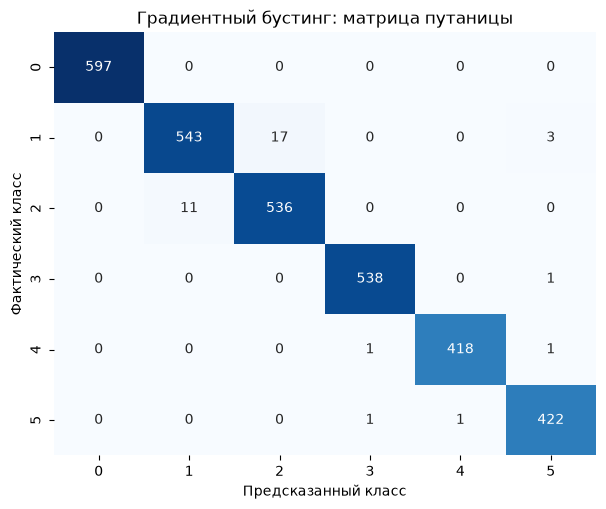

In [12]:
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set(xlabel='Предсказанный класс', ylabel='Фактический класс', title=title)
    return cm

plot_cm(y_test, y_pred_gbc, 'Градиентный бустинг: матрица путаницы');
print(dict(zip(range(len(le.classes_)), le.classes_)))

### Выводы к вопросу 4

* Поиск по сетке (3 значения `n_estimators`, 2 — `learning_rate`, 2 — `subsample`, 2 — `max_features`, 3-кратная кросс-валидация) выбрал `n_estimators = 400`, `learning_rate = 0,1`, `subsample = 0,5`, `max_features = 8`; точность кросс-валидации 0,987.
* На тесте accuracy = 0,9883, а precision, recall и F1 по всем классам не ниже 0,96. Идеально (1,00) распознаются лежание, ходьба и спуск по лестнице.
* **Матрица путаницы:** почти все ошибки — между классами 1 (SITTING) и 2 (STANDING): 17 сидений приняты за стояние и 11 стояний за сидение (28 из 36 ошибок). Эти позы статичны и дают очень похожие сигналы датчиков.
* Подвыборка 0,5 (стохастический бустинг) и меньший шаг обучения повышают устойчивость модели и снижают переобучение.

## Вопрос 5. AdaBoost

На данном этапе выполняется:

- построение модели AdaBoost и её подбор поиском по сетке (число оценок от 100 до 200);
- сравнение ошибок AdaBoost и градиентного бустинга.

Базовым классификатором служит дерево решений с `max_features=4` для ускорения сходимости.

In [13]:
param_grid = {'n_estimators': [100, 150, 200],
              'learning_rate': [1.0, 0.5, 0.1],
              'estimator__max_depth': [1, 2, 3]}

ABC = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_features=4, random_state=42), random_state=42)
GV_ABC = GridSearchCV(ABC, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1)
GV_ABC = GV_ABC.fit(X_train, y_train)
abc_best = GV_ABC.best_estimator_

print('Лучшие параметры:', GV_ABC.best_params_)
print('Точность кросс-валидации:', round(GV_ABC.best_score_, 4))

Лучшие параметры: {'estimator__max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 200}
Точность кросс-валидации: 0.9594


Показатели ошибок.

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.93      0.92      0.92       563
          STANDING       0.92      0.93      0.92       547
           WALKING       0.99      0.99      0.99       539
WALKING_DOWNSTAIRS       0.99      0.98      0.99       420
  WALKING_UPSTAIRS       0.97      0.99      0.98       424

          accuracy                           0.96      3090
         macro avg       0.97      0.97      0.97      3090
      weighted avg       0.96      0.96      0.96      3090

accuracy на тесте: 0.9647


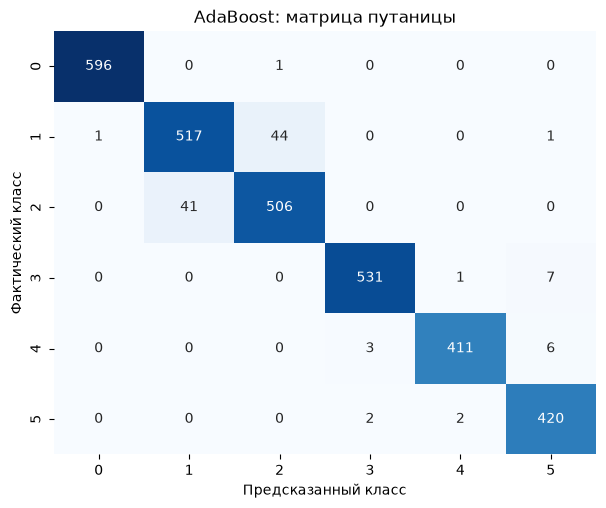

In [14]:
y_pred_abc = abc_best.predict(X_test)
print(classification_report(y_test, y_pred_abc, target_names=le.classes_))
print('accuracy на тесте:', round(accuracy_score(y_test, y_pred_abc), 4))
plot_cm(y_test, y_pred_abc, 'AdaBoost: матрица путаницы');

Сравнение двух моделей.

In [15]:
from sklearn.metrics import precision_recall_fscore_support
def summary(y_true, y_pred, name):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred), 'precision': p, 'recall': r, 'f1': f}, name=name)

pd.concat([summary(y_test, y_pred_gbc, 'GradientBoosting'),
           summary(y_test, y_pred_abc, 'AdaBoost')], axis=1).round(4)

,GradientBoosting,AdaBoost
accuracy,0.9883,0.9647
precision,0.9884,0.9648
recall,0.9883,0.9647
f1,0.9883,0.9647


### Выводы к вопросу 5

* Поиск по сетке для AdaBoost выбрал `n_estimators = 200`, `learning_rate = 0,5` и базовое дерево глубины 3; точность кросс-валидации 0,959.
* На тесте AdaBoost даёт accuracy = 0,9647 против 0,9883 у градиентного бустинга: **AdaBoost хуже на 2,4 п.п.**, при этом число ошибок выросло с 36 до 109.
* Проблема сидения/стояния усугубилась (44 + 41 = 85 ошибок против 28), а также появились ошибки между ходьбой, подъёмом и спуском по лестнице (классы 3–5), которых почти не было у градиентного бустинга.
* Причина: AdaBoost на каждом шаге повышает веса неправильно классифицированных объектов, поэтому он чувствителен к выбросам и шуму, а градиентный бустинг (с подвыборкой) более устойчив. Для этих данных лучше градиентный бустинг.

## Вопрос 6. Логистическая регрессия и объединение моделей

На данном этапе выполняется:

- построение модели логистической регрессии с регуляризацией (`LogisticRegressionCV`, L2-регуляризация, коэффициент регуляризации подбирается кросс-валидацией);
- объединение логистической регрессии с моделями градиентного бустинга и AdaBoost из вопросов 4 и 5 с помощью `VotingClassifier`;
- расчёт ошибок и сравнение с отдельными моделями;
- построение матрицы путаницы для лучшей модели.

In [16]:
lr = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10, 100], cv=4, max_iter=1000, random_state=42, n_jobs=-1)
lr = lr.fit(X_train, y_train)
print('Выбранное значение C:', lr.C_[0])

Выбранное значение C: 10.0


Ошибки и матрица путаницы для логистической регрессии.

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.96      0.95      0.95       563
          STANDING       0.96      0.95      0.96       547
           WALKING       0.99      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      0.99      1.00       420
  WALKING_UPSTAIRS       0.98      1.00      0.99       424

          accuracy                           0.98      3090
         macro avg       0.98      0.98      0.98      3090
      weighted avg       0.98      0.98      0.98      3090



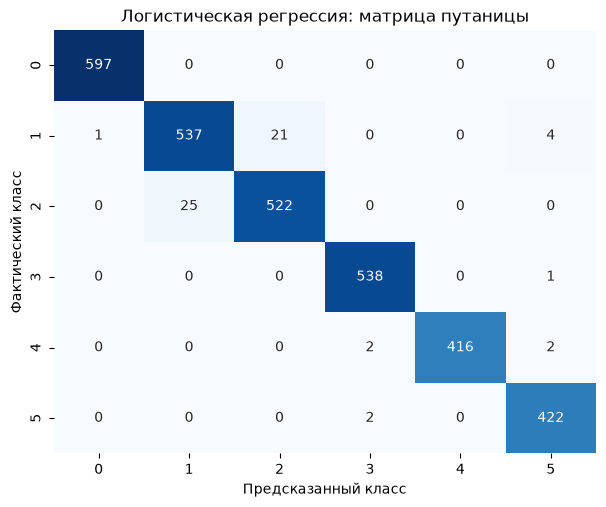

In [17]:
y_pred_lr = lr.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))
plot_cm(y_test, y_pred_lr, 'Логистическая регрессия: матрица путаницы');

Теперь — объединённая модель (`VotingClassifier` с мягким голосованием: усредняются вероятности классов трёх моделей).

In [18]:
vc = VotingClassifier(estimators=[('lr', LogisticRegressionCV(Cs=[lr.C_[0]], cv=4, max_iter=1000, random_state=42)),
                                  ('gbc', GradientBoostingClassifier(**GV_GBC.best_params_, random_state=42)),
                                  ('abc', AdaBoostClassifier(estimator=DecisionTreeClassifier(
                                      max_features=4, max_depth=GV_ABC.best_params_['estimator__max_depth'], random_state=42),
                                      n_estimators=GV_ABC.best_params_['n_estimators'],
                                      learning_rate=GV_ABC.best_params_['learning_rate'], random_state=42))],
                      voting='soft', n_jobs=-1)
vc = vc.fit(X_train, y_train)
y_pred_vc = vc.predict(X_test)
print(classification_report(y_test, y_pred_vc, target_names=le.classes_))

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       597
           SITTING       0.97      0.96      0.97       563
          STANDING       0.97      0.97      0.97       547
           WALKING       1.00      1.00      1.00       539
WALKING_DOWNSTAIRS       1.00      1.00      1.00       420
  WALKING_UPSTAIRS       0.99      1.00      0.99       424

          accuracy                           0.99      3090
         macro avg       0.99      0.99      0.99      3090
      weighted avg       0.99      0.99      0.99      3090



Сравнение всех моделей.

In [19]:
results = pd.concat([summary(y_test, y_pred_lr, 'LogisticRegression'),
                     summary(y_test, y_pred_gbc, 'GradientBoosting'),
                     summary(y_test, y_pred_abc, 'AdaBoost'),
                     summary(y_test, y_pred_vc, 'Voting (LR+GB+Ada)')], axis=1).T
results.round(4)

,accuracy,precision,recall,f1
LogisticRegression,0.9812,0.9812,0.9812,0.9812
GradientBoosting,0.9883,0.9884,0.9883,0.9883
AdaBoost,0.9647,0.9648,0.9647,0.9647
Voting (LR+GB+Ada),0.9864,0.9864,0.9864,0.9864


Матрица путаницы для лучшей модели.

Лучшая модель: GradientBoosting


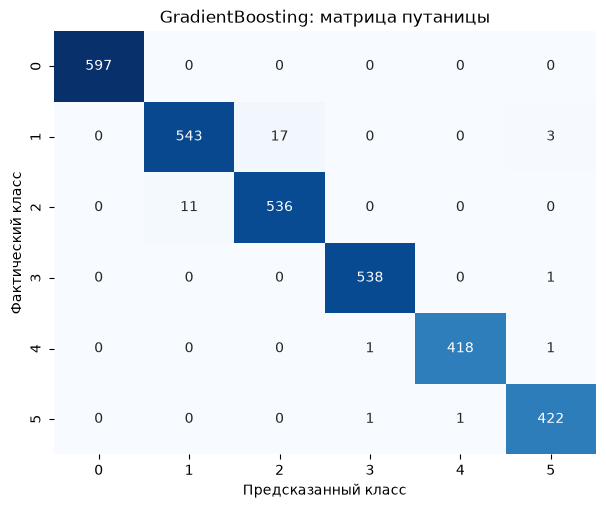

In [20]:
best_name = results['accuracy'].idxmax()
best_pred = {'LogisticRegression': y_pred_lr, 'GradientBoosting': y_pred_gbc,
             'AdaBoost': y_pred_abc, 'Voting (LR+GB+Ada)': y_pred_vc}[best_name]
print('Лучшая модель:', best_name)
plot_cm(y_test, best_pred, f'{best_name}: матрица путаницы');

### Выводы к вопросу 6

* **Логистическая регрессия** с L2-регуляризацией (лучшее `C = 10`, выбрано кросс-валидацией) даёт accuracy = 0,9812 — лишь немного ниже градиентного бустинга (0,9883) и заметно выше AdaBoost (0,9647). Её ошибки — тоже в основном сидение/стояние. Это напоминание, что **сначала стоит пробовать самую простую модель**: здесь она почти не уступает сложной и обучается намного быстрее.
* **VotingClassifier** (мягкое голосование логистической регрессии, градиентного бустинга и AdaBoost) даёт accuracy = 0,9864. Он лучше логистической регрессии и AdaBoost, но **не превзошёл** отдельный градиентный бустинг (0,9883): слабая модель AdaBoost тянет усреднённые вероятности вниз.
* **Лучшая модель набора упражнений — градиентный бустинг** (accuracy = 0,9883). Матрица путаницы показывает, что остаточные ошибки сосредоточены в различении SITTING и STANDING.
* Объединение моделей оправдано, когда они делают *разные* ошибки; здесь ошибки моделей сильно совпадают, поэтому выигрыш отсутствует.

### Общие выводы

* **Бустинг** обучает слабые модели (неглубокие деревья) последовательно, и каждая следующая исправляет ошибки предыдущих; он снижает как смещение, так и дисперсию (в отличие от баггинга, снижающего в основном дисперсию).
* Точность градиентного бустинга растёт с числом деревьев и выходит на плато (0,987 при 400); подбор параметров (`learning_rate`, `subsample`, `max_features`) дал 0,9883 на тесте.
* AdaBoost (0,9647) уступил градиентному бустингу из-за чувствительности к выбросам; логистическая регрессия (0,9812) оказалась сильным простым базовым решением.
* Голосование (0,9864) улучшило слабые модели, но не превзошло лучшую одиночную; главная трудность всех моделей — различение сидения и стояния.